# EMQA_L3_vol_level

**Monthly standard deviation of the daily EUR/MWh shocks of the Romanian base price against the monthly mean price, 2019-01-01 to 2026-10-31, log-log scales, coloured by year, with the log-log regression line: volatility in EUR/MWh grows with the price level.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_vol_level/EMQA_L3_vol_level.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Volatility grows with the price level

For each month $m$: $\hat\sigma_m(u)$ = standard deviation of the daily EUR/MWh shocks, $\bar P_m$ = mean price. OLS regression $\ln\hat\sigma_m(u)=a+b\ln\bar P_m+e_m$ (and the same with the percent shocks).

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


### Numbers on the slide

In [6]:
m = pd.DataFrame({'sd': E_EUR.groupby(E_EUR.index.to_period('M')).std(), 'lvl': P.groupby(P.index.to_period('M')).mean()}).dropna()
ll = sm.OLS(np.log(m['sd']), sm.add_constant(np.log(m['lvl']))).fit()
mp = pd.DataFrame({'sd': E_PCT.groupby(E_PCT.index.to_period('M')).std(), 'lvl': m['lvl']}).dropna()
lp = sm.OLS(np.log(mp['sd']), sm.add_constant(np.log(mp['lvl']))).fit()
slide('months', 'level.n', len(m))
slide('slope, EUR/MWh volatility on price level', 'level.slope', ll.params.iloc[1], 2)
slide('  R^2', 'level.r2', ll.rsquared, 2)
slide('slope, percent volatility on price level', 'level.slope_pct', lp.params.iloc[1], 2)
slide('  R^2', 'level.r2_pct', lp.rsquared, 2)

months                                                     94   [level.n]
slope, EUR/MWh volatility on price level                   0.75   [level.slope]
  R^2                                                      0.76   [level.r2]
slope, percent volatility on price level                   0.01   [level.slope_pct]
  R^2                                                      0.0   [level.r2_pct]


### Chart

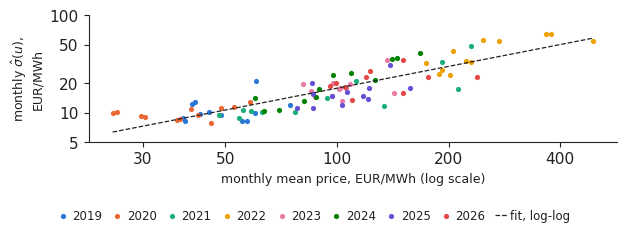

In [7]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
fig, ax = plt.subplots(figsize=(6.4, 2.4))
yrs = m.index.year
for y in range(START.year, END.year + 1):
    ax.scatter(m['lvl'][yrs == y], m['sd'][yrs == y], s=14, color=SERIES[(y - START.year) % 8], label=str(y), lw=0)
xx = np.linspace(m['lvl'].min(), m['lvl'].max(), 50)
ax.plot(xx, np.exp(ll.params.iloc[0]) * xx ** ll.params.iloc[1], color='#222222', lw=0.9, ls='--', label='fit, log-log')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([30, 50, 100, 200, 400])
ax.set_xticklabels(['30', '50', '100', '200', '400'])
ax.set_yticks([5, 10, 20, 50, 100])
ax.set_yticklabels(['5', '10', '20', '50', '100'])
ax.minorticks_off()
ax.set_xlabel('monthly mean price, EUR/MWh (log scale)', fontsize=9)
ax.set_ylabel('monthly $\\hat\\sigma(u)$,\nEUR/MWh', fontsize=9)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=9, bbox_to_anchor=(0.5, 0.0), frameon=False,
           fontsize=8.5, handlelength=1.0, columnspacing=0.8, handletextpad=0.3)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.savefig('vol_level.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()